In [2]:
import numpy as np
import pandas as pd
from xgboost import XGBRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error

np.random.seed(42)
n_samples = 200

X = np.arange(n_samples).reshape(-1, 1) 
y = 0.5 * X.flatten() + 10 * np.sin(X.flatten() / 5) + np.random.normal(0, 2, n_samples)
split_point = int(n_samples * 0.8)
X_train_full, X_test = X[:split_point], X[split_point:]
y_train_full, y_test = y[:split_point], y[split_point:]

param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7]
}

base_model = XGBRegressor(
    subsample=0.8,      
    random_state=42
)
tscv_tuning = TimeSeriesSplit(n_splits=3)

grid_search = GridSearchCV(
    estimator=base_model,
    param_grid=param_grid,
    cv=tscv_tuning,      
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
)

grid_search.fit(X_train_full, y_train_full)

print("\n=== HASIL TUNING ===")
print("Parameter Terbaik:", grid_search.best_params_)
# Nilai dikalikan -1 karena scoring menggunakan 'neg_mean_absolute_error'
print(f"MAE Validasi Terbaik: {-grid_search.best_score_:.2f}")


=== HASIL TUNING ===
Parameter Terbaik: {'learning_rate': 0.2, 'max_depth': 5, 'n_estimators': 100}
MAE Validasi Terbaik: 13.56


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.deterministic import DeterministicProcess

np.random.seed(42)
waktu = pd.date_range("2020-01-01", periods=500, freq="D")
tren = np.linspace(10, 100, 500)
musiman = np.sin(np.arange(500) * (2 * np.pi / 30)) * 20 # Siklus 30 harian
penjualan = tren + musiman + np.random.normal(0, 5, 500)

df = pd.DataFrame({'Sales': penjualan}, index=waktu)

test_size = 60
df_train = df.iloc[:-test_size].copy()
df_test = df.iloc[-test_size:].copy()

In [4]:
# Pembuatan Fitur Waktu (Tren)
dp = DeterministicProcess(index=df.index, order=1, constant=True)
X_trend_full = dp.in_sample()

X_trend_train = X_trend_full.iloc[:-test_size]
X_trend_test = X_trend_full.iloc[-test_size:]

# Pelatihan Model Tren (Regresi Linear)
model_trend = LinearRegression()
model_trend.fit(X_trend_train, df_train['Sales'])

# Menyimpan prediksi tren
pred_trend_train = pd.Series(model_trend.predict(X_trend_train), index=df_train.index)
pred_trend_test = pd.Series(model_trend.predict(X_trend_test), index=df_test.index)

# Ekstraksi Residual pada data pelatihan
residual_train = df_train['Sales'] - pred_trend_train

X_season_full = pd.DataFrame({'Cycle_30': np.arange(len(df)) % 30}, index=df.index)

X_season_train = X_season_full.iloc[:-test_size]
X_season_test = X_season_full.iloc[-test_size:]

In [5]:
# Pengaturan Grid Parameter
param_grid = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 5],
    'subsample': [0.8, 1.0]
}

# Pengaturan Time Series Split (5 Lipatan pada sisa data latih)
tscv = TimeSeriesSplit(n_splits=5)

# Eksekusi Grid Search
grid_search = GridSearchCV(
    estimator=XGBRegressor(random_state=42),
    param_grid=param_grid,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

grid_search.fit(X_season_train, residual_train)

# Ekstraksi model XGBoost terbaik
best_xgb_model = grid_search.best_estimator_

print("Parameter XGBoost Terbaik:", grid_search.best_params_)

Parameter XGBoost Terbaik: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 50, 'subsample': 0.8}


Mean Absolute Error (Test Set): 4.23


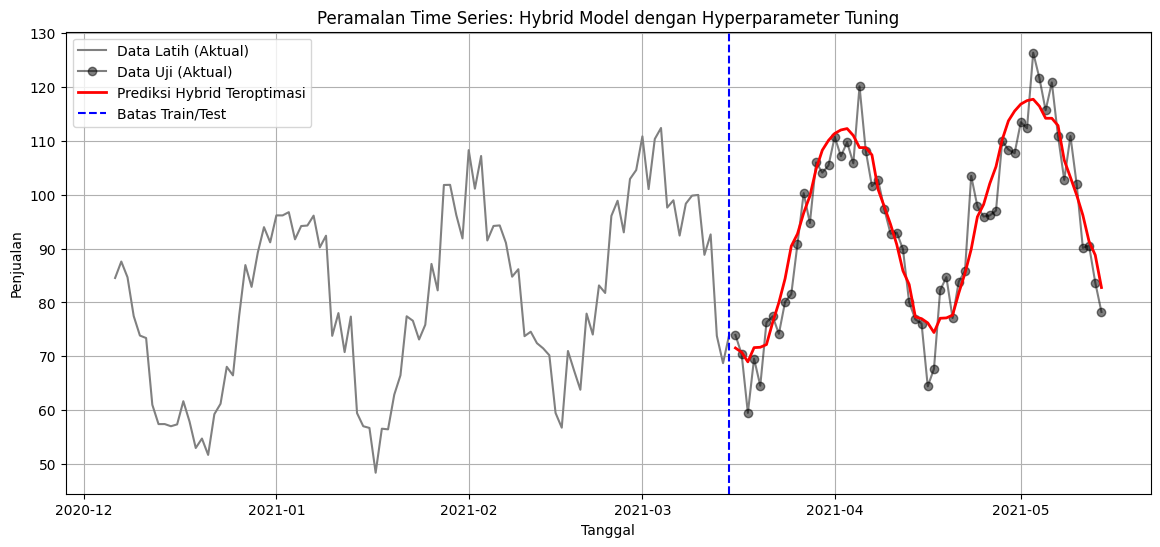

In [6]:
# Prediksi residual pada set pengujian menggunakan model XGBoost terbaik
pred_residual_test = pd.Series(best_xgb_model.predict(X_season_test), index=df_test.index)

# REKONSTRUKSI: Final Prediksi = Prediksi Tren + Prediksi Residual
pred_final_test = pred_trend_test + pred_residual_test

# Evaluasi Akhir
mae = mean_absolute_error(df_test['Sales'], pred_final_test)
print(f"Mean Absolute Error (Test Set): {mae:.2f}")

# Visualisasi
plt.figure(figsize=(14, 6))

# Plot Data Historis (Sebagian agar lebih jelas)
plt.plot(df_train.index[-100:], df_train['Sales'].iloc[-100:], label='Data Latih (Aktual)', color='gray')

# Plot Data Aktual Test Set
plt.plot(df_test.index, df_test['Sales'], label='Data Uji (Aktual)', marker='o', color='black', alpha=0.5)

# Plot Hasil Forecasting Final
plt.plot(df_test.index, pred_final_test, label='Prediksi Hybrid Teroptimasi', color='red', linewidth=2)

plt.title("Peramalan Time Series: Hybrid Model dengan Hyperparameter Tuning")
plt.xlabel("Tanggal")
plt.ylabel("Penjualan")
plt.axvline(x=df_train.index[-1], color='blue', linestyle='--', label='Batas Train/Test')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# model = XGBRegressor(n_estimators = 50, learning_rate = 0.05, max_depth = 3, subsample = 0.8)

# Pengaturan Grid Parameter
param_grid = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 5],
    'subsample': [0.8, 1.0]
}

# Pengaturan Time Series Split (5 Lipatan pada sisa data latih)
tscv = TimeSeriesSplit(n_splits=5)

# Eksekusi Grid Search
grid_search = GridSearchCV(
    estimator=XGBRegressor(random_state=42),
    param_grid=param_grid,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

grid_search.fit(X_season_train, residual_train)

# Ekstraksi model XGBoost terbaik
best_xgb_model = grid_search.best_estimator_

print("Parameter XGBoost Terbaik:", grid_search.best_params_)

In [ ]:
y = 0.5 * X.flatten() + 10 * np.sin(X.flatten() / 5) + np.random.normal(0, 2, n_samples)

